# Topic 30: Kernel Density Estimation — Reference Notebook

**Track 8, topic 2 of 4 · High-Dimensional & Nonparametric**

This notebook produces the **9 figures** for the Topic 30 MDX and prints **14 test-pin expected values** for `src/components/viz/shared/nonparametric.test.ts` (T30.1 – T30.14).

**How to use:**
1. Run all cells top-to-bottom.
2. Figures land in `public/images/topics/kernel-density-estimation/` (relative to notebook location).
3. Cell 14 prints the 14 test-pin expected values — copy these into `nonparametric.test.ts`.

**Conventions (Track-8 inherited):**
- `np.random.seed(42)` for all stochastic steps.
- Figures saved at `dpi=150, bbox_inches='tight'`.
- Track-8 palette: KDE violet `#7C3AED`, bias amber `#D97706`, variance blue `#2563EB`, MISE rose `#E11D48`.

**Section map (9 figures, mapped to MDX §):**

| Cell | Fig | § | Purpose |
|------|-----|---|---------|
| 4 | 1 | 30.1 | Histogram vs KDE at 3 bandwidths, motivation |
| 5 | 2 | 30.3 | 5-kernel family overlay |
| 6 | 3 | 30.5 | Bias² / variance / MISE vs $h$ decomposition |
| 7 | 4 | 30.5 | Boundary-bias demo: Beta(2,5) |
| 8 | 5 | 30.6 | AMISE curves across 4 kernels (featured) |
| 9 | 6 | 30.6 | $\mathrm{AMISE}^*$ vs $n$ log-log $n^{-4/5}$ rate |
| 10 | 7 | 30.7 | Pointwise CI coverage |
| 11 | 8 | 30.8 | Silverman vs UCV vs SHJ on bimodal |
| 12 | 9 | 30.10 | Track 8 forward-map update |


In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Rectangle
from matplotlib.lines import Line2D
from pathlib import Path

import scipy
import scipy.stats as stats
from scipy.stats import norm, beta as beta_dist, uniform, t as t_dist
from scipy.special import gammaln
from scipy.integrate import quad

# Track 8 seeding convention (inherits Topic 29).
SEED = 42
np.random.seed(SEED)
rng = np.random.default_rng(SEED)

# Output directory (relative to notebook location).
OUTPUT_DIR = Path('public/images/topics/kernel-density-estimation')
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

print(f'NumPy {np.__version__}  ·  SciPy {scipy.__version__}')
print(f'Output directory: {OUTPUT_DIR.resolve()}')
print(f'Seed: {SEED}')

NumPy 2.5.4  ·  SciPy 1.18.1
Output directory: /Users/jonathanrocha/Developer/Sites/formalStatistics-kde-fig8/notebooks/kernel-density-estimation/public/images/topics/kernel-density-estimation
Seed: 42


In [2]:
# Inherits Topic 29's Track-8 accents:
COLOR_ECDF       = '#2563EB'   # blue-600    — Topic 29's ECDF token (reused for true-density overlays)
COLOR_DKW        = '#14B8A6'   # teal-500
COLOR_BAHADUR    = '#7C3AED'   # violet-600
COLOR_KS         = '#F97316'   # orange-500

# NEW — Topic 30 accent tokens.
COLOR_KDE        = '#7C3AED'   # violet-600  — primary KDE curve
COLOR_BIAS       = '#D97706'   # amber-600   — bias² curves
COLOR_VARIANCE   = '#2563EB'   # blue-600    — variance curves
COLOR_MISE       = '#E11D48'   # rose-600    — MISE curves
COLOR_TRUE       = '#111827'   # gray-900    — true density overlay (black-ish)

# Five-kernel palette (Fig 2, Fig 5).
KERNEL_COLORS = {
    'gaussian':     '#2563EB',  # blue
    'epanechnikov': '#7C3AED',  # violet (optimum)
    'biweight':     '#059669',  # emerald
    'triangular':   '#D97706',  # amber
    'uniform':      '#94A3B8',  # slate (lowest efficiency)
}

# Bandwidth-selector palette (Fig 8).
SELECTOR_COLORS = {
    'silverman':      '#4F46E5',  # indigo
    'scott':          '#94A3B8',  # slate
    'ucv':            '#D97706',  # amber
    'sheather_jones': '#7C3AED',  # violet
}

plt.rcParams.update({
    'font.family': 'serif',
    'font.size': 10,
    'axes.titlesize': 11,
    'axes.labelsize': 10,
    'axes.spines.top': False,
    'axes.spines.right': False,
    'axes.grid': True,
    'grid.alpha': 0.3,
    'grid.linestyle': '--',
    'grid.linewidth': 0.5,
    'figure.dpi': 100,
    'savefig.dpi': 150,
    'savefig.bbox': 'tight',
    'mathtext.fontset': 'cm',
})

SAVE_KW = dict(dpi=150, bbox_inches='tight', pad_inches=0.15)
print('Palette locked (KDE violet · Bias amber · Variance blue · MISE rose · 5-kernel family · 4-selector).')

Palette locked (KDE violet · Bias amber · Variance blue · MISE rose · 5-kernel family · 4-selector).


In [3]:
# ────────────────────────────────────────────────────────────────────────────
# Kernel functions — matches the TypeScript shared module (nonparametric.ts §8).
# All are symmetric densities with ∫K = 1.
# ────────────────────────────────────────────────────────────────────────────

def gaussian_kernel(u):
    """K(u) = (1/√(2π)) exp(-u²/2); infinite support."""
    return np.exp(-0.5 * u * u) / np.sqrt(2 * np.pi)

def epanechnikov_kernel(u):
    """K_E(u) = (3/4)(1 - u²) on [-1, 1], 0 outside. MISE-optimal."""
    u = np.asarray(u)
    return np.where(np.abs(u) <= 1, 0.75 * (1 - u*u), 0.0)

def biweight_kernel(u):
    """K(u) = (15/16)(1 - u²)² on [-1, 1], 0 outside."""
    u = np.asarray(u)
    mask = np.abs(u) <= 1
    return np.where(mask, (15/16) * (1 - u*u)**2, 0.0)

def triangular_kernel(u):
    """K(u) = (1 - |u|) on [-1, 1], 0 outside."""
    u = np.asarray(u)
    return np.where(np.abs(u) <= 1, 1 - np.abs(u), 0.0)

def uniform_kernel(u):
    """K(u) = 1/2 on [-1, 1], 0 outside."""
    u = np.asarray(u)
    return np.where(np.abs(u) <= 1, 0.5, 0.0)

KERNELS = {
    'gaussian':     gaussian_kernel,
    'epanechnikov': epanechnikov_kernel,
    'biweight':     biweight_kernel,
    'triangular':   triangular_kernel,
    'uniform':      uniform_kernel,
}

# Closed-form kernel properties (also in nonparametric.ts kernelProperties()).
KERNEL_PROPS = {
    'gaussian':     dict(R=1/(2*np.sqrt(np.pi)), mu2=1.0,      support=(-np.inf, np.inf), efficiency=0.951),
    'epanechnikov': dict(R=3/5,                  mu2=1/5,      support=(-1, 1),           efficiency=1.000),
    'biweight':     dict(R=5/7,                  mu2=1/7,      support=(-1, 1),           efficiency=0.994),
    'triangular':   dict(R=2/3,                  mu2=1/6,      support=(-1, 1),           efficiency=0.986),
    'uniform':      dict(R=1/2,                  mu2=1/3,      support=(-1, 1),           efficiency=0.930),
}

# ────────────────────────────────────────────────────────────────────────────
# KDE evaluator.
#   f̂_h(x) = (1/nh) Σ K((x - X_i)/h)
# ────────────────────────────────────────────────────────────────────────────

def kde_evaluate(sample, x, h, kernel=gaussian_kernel):
    """Evaluate f̂_h(x) at scalar or array-valued x."""
    sample = np.asarray(sample)
    x = np.atleast_1d(x)
    n = len(sample)
    # Broadcast (len(x), n) matrix of K((x - X_i)/h).
    u = (x[:, None] - sample[None, :]) / h
    return kernel(u).sum(axis=1) / (n * h)

# ────────────────────────────────────────────────────────────────────────────
# Bandwidth selectors (Silverman, Scott, UCV — matches nonparametric.ts §10).
# ────────────────────────────────────────────────────────────────────────────

def silverman_bandwidth(sample):
    """ĥ_ROT = 1.06 · min(SD, IQR/1.34) · n^(-1/5)  (SIL1986)."""
    sample = np.asarray(sample)
    n = len(sample)
    sd = np.std(sample, ddof=1)
    q1, q3 = np.quantile(sample, [0.25, 0.75])
    iqr_scaled = (q3 - q1) / 1.34
    sigma_hat = min(sd, iqr_scaled) if iqr_scaled > 0 else sd
    return 1.06 * sigma_hat * n**(-1/5)

def scott_bandwidth(sample):
    """ĥ_S = 1.06 · SD · n^(-1/5)  (SCO2015)."""
    sample = np.asarray(sample)
    n = len(sample)
    return 1.06 * np.std(sample, ddof=1) * n**(-1/5)

def ucv_objective(sample, h, kernel=gaussian_kernel):
    """UCV(h) = ∫ f̂_h² - (2/n) Σ f̂_{h,-i}(X_i).
    Leave-one-out bandwidth-CV score; minimize over h."""
    n = len(sample)
    pad = 4 * h
    grid = np.linspace(sample.min() - pad, sample.max() + pad, 300)
    dx = grid[1] - grid[0]
    f_hat = kde_evaluate(sample, grid, h, kernel)
    integral_fh_sq = (f_hat ** 2).sum() * dx
    # Leave-one-out term.
    loo_sum = 0.0
    for i in range(n):
        mask = np.arange(n) != i
        xi = sample[i]
        others = sample[mask]
        loo_sum += kernel((xi - others) / h).sum() / ((n - 1) * h)
    return integral_fh_sq - 2 * loo_sum / n

def ucv_bandwidth(sample, kernel=gaussian_kernel, n_grid=30):
    """UCV bandwidth by grid search over [0.1·h_S, 2·h_S]."""
    h_s = silverman_bandwidth(sample)
    h_grid = np.logspace(np.log10(0.1 * h_s), np.log10(2 * h_s), n_grid)
    scores = np.array([ucv_objective(sample, h, kernel) for h in h_grid])
    return h_grid[np.argmin(scores)]

def sheather_jones_bandwidth(sample):
    """Sheather-Jones one-step direct plug-in (WAN1995 §3.6) — matches
    `sheatherJonesBandwidth` in PluginBandwidthComparator.tsx.
    Pilot g = Silverman; R̂(f'') = n⁻² g⁻⁵ Σᵢ Σⱼ φ⁽⁴⁾((Xᵢ − Xⱼ)/g),
    with Gaussian φ⁽⁴⁾(u) = (u⁴ − 6u² + 3) φ(u); then the AMISE-optimal h."""
    sample = np.asarray(sample)
    n = len(sample)
    g = silverman_bandwidth(sample)
    u = (sample[:, None] - sample[None, :]) / g
    phi4 = (u**4 - 6 * u**2 + 3) * np.exp(-0.5 * u**2) / np.sqrt(2 * np.pi)
    R_f_dd_hat = max(phi4.sum() / (n**2 * g**5), 1e-10)
    # AMISE-optimal h with R(K_gaussian) = 1/(2√π), mu2 = 1:
    return (1 / (2 * np.sqrt(np.pi)) / (n * R_f_dd_hat))**(1/5)

def amise_optimal_bandwidth(R_f_dd, n, kernel_name='gaussian'):
    """h* = (R(K) / (n · μ₂(K)² · R(f'')))^{1/5}  (§30.6 Thm 4)."""
    props = KERNEL_PROPS[kernel_name]
    R, mu2 = props['R'], props['mu2']
    return (R / (n * mu2**2 * R_f_dd))**(1/5)

def amise_value(R_f_dd, n, h, kernel_name='gaussian'):
    """AMISE(h) = R(K)/(nh) + h⁴ μ₂(K)² R(f'') / 4."""
    props = KERNEL_PROPS[kernel_name]
    R, mu2 = props['R'], props['mu2']
    return R/(n*h) + h**4 * mu2**2 * R_f_dd / 4

# Closed-form curvature integrals for the three Topic-30 presets.
R_F_DD_NORMAL = 3 / (8 * np.sqrt(np.pi))   # ≈ 0.211755

def normal_pdf_d2(x):
    """d²/dx² φ(x) = (x² - 1) φ(x)."""
    return (x**2 - 1) * np.exp(-0.5 * x**2) / np.sqrt(2 * np.pi)

def bimodal_pdf(x, mu=1.5):
    """0.5 N(-μ, 1) + 0.5 N(μ, 1)."""
    return 0.5 * (norm.pdf(x, loc=-mu, scale=1) + norm.pdf(x, loc=mu, scale=1))

def bimodal_pdf_d2(x, mu=1.5):
    """d²/dx² [0.5 φ(x+μ) + 0.5 φ(x-μ)]."""
    p1 = norm.pdf(x, loc=-mu, scale=1)
    p2 = norm.pdf(x, loc=mu, scale=1)
    return 0.5 * ((x + mu)**2 - 1) * p1 + 0.5 * ((x - mu)**2 - 1) * p2

def beta_25_pdf(x):
    x = np.asarray(x)
    return np.where((x >= 0) & (x <= 1), 30 * x * (1 - x)**4, 0.0)

def beta_25_pdf_d2(x):
    """f''(x) for Beta(2,5): f = 30 x (1-x)^4 → f'' = 60 (1-x)² (10x - 4)."""
    x = np.asarray(x)
    return np.where((x >= 0) & (x <= 1), 60 * (1 - x)**2 * (10 * x - 4), 0.0)

# Numerical R(f'') for bimodal and beta, for the oracle AMISE calculations.
R_F_DD_BIMODAL, _ = quad(lambda x: bimodal_pdf_d2(x)**2, -8, 8, limit=200)
R_F_DD_BETA25, _ = quad(lambda x: beta_25_pdf_d2(x)**2, 0.001, 0.999, limit=200)

print(f'R(f") for N(0,1):     {R_F_DD_NORMAL:.6f}  (closed form = 3/(8√π))')
print(f'R(f") for Bimodal:    {R_F_DD_BIMODAL:.6f}  (numerical)')
print(f'R(f") for Beta(2,5):  {R_F_DD_BETA25:.4f}  (numerical)')
print()
print('Kernel & KDE utilities ready.')

R(f") for N(0,1):     0.211571  (closed form = 3/(8√π))
R(f") for Bimodal:    0.091848  (numerical)
R(f") for Beta(2,5):  5291.2300  (numerical)

Kernel & KDE utilities ready.


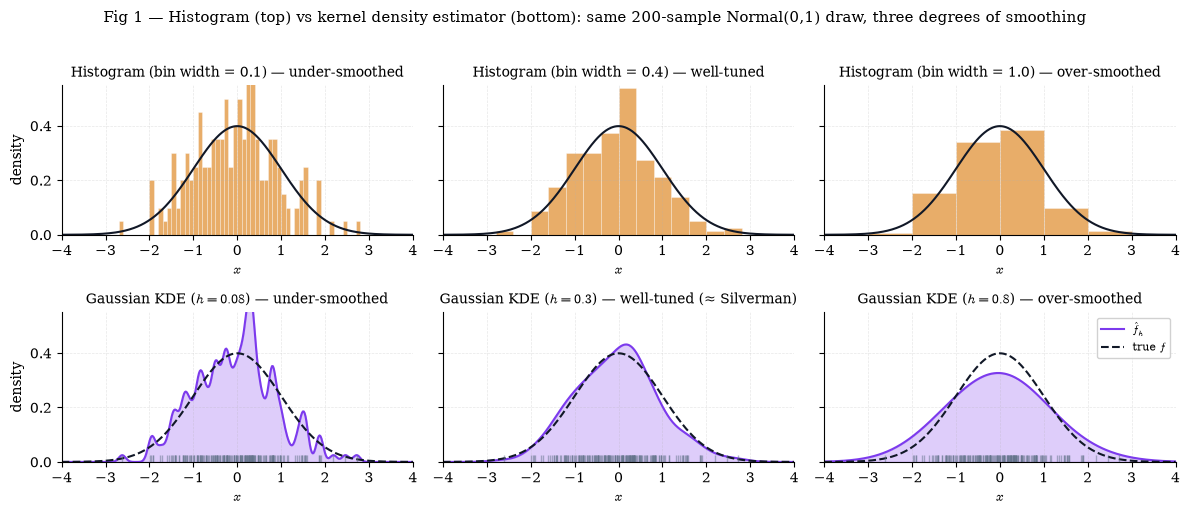

Saved: 30-histogram-to-kde.png
Silverman bandwidth for this sample: ĥ = 0.3306


In [4]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 1 (§30.1): Histogram-to-KDE motivation.
#   Top row: three histograms at bin widths 0.1, 0.4, 1.0.
#   Bottom row: three Gaussian-KDE curves at bandwidths 0.08, 0.3, 0.8.
#   Same 200-sample Normal(0,1) draw across all six panels.
# ═══════════════════════════════════════════════════════════════════════════
np.random.seed(42)
n = 200
sample = np.random.standard_normal(n)
grid = np.linspace(-4, 4, 400)
true_pdf = norm.pdf(grid)

fig, axes = plt.subplots(2, 3, figsize=(12, 5), sharey='row')

# Top row: histograms at three bin widths.
bin_widths = [0.1, 0.4, 1.0]
bin_labels = ['under-smoothed', 'well-tuned', 'over-smoothed']
for ax, b, lab in zip(axes[0], bin_widths, bin_labels):
    bins = np.arange(-4, 4 + b, b)
    ax.hist(sample, bins=bins, density=True, color=COLOR_BIAS, alpha=0.6, edgecolor='white', linewidth=0.4)
    ax.plot(grid, true_pdf, color=COLOR_TRUE, linewidth=1.5, label='true $f$')
    ax.set_title(f'Histogram (bin width = {b}) — {lab}', fontsize=10)
    ax.set_xlabel('$x$')
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.55)
axes[0, 0].set_ylabel('density')

# Bottom row: Gaussian KDE curves at three bandwidths.
bandwidths = [0.08, 0.3, 0.8]
h_labels = ['under-smoothed', 'well-tuned (≈ Silverman)', 'over-smoothed']
for ax, h, lab in zip(axes[1], bandwidths, h_labels):
    fhat = kde_evaluate(sample, grid, h, gaussian_kernel)
    ax.fill_between(grid, 0, fhat, color=COLOR_KDE, alpha=0.25)
    ax.plot(grid, fhat, color=COLOR_KDE, linewidth=1.5, label='$\\hat f_h$')
    ax.plot(grid, true_pdf, color=COLOR_TRUE, linewidth=1.5, linestyle='--', label='true $f$')
    # Data tick marks.
    ax.plot(sample, np.zeros_like(sample) + 0.01, '|', color='#64748B', markersize=6, alpha=0.5)
    ax.set_title(f'Gaussian KDE ($h = {h}$) — {lab}', fontsize=10)
    ax.set_xlabel('$x$')
    ax.set_xlim(-4, 4)
    ax.set_ylim(0, 0.55)
    if ax is axes[1, 2]:
        ax.legend(loc='upper right', fontsize=8, framealpha=0.9)
axes[1, 0].set_ylabel('density')

fig.suptitle('Fig 1 — Histogram (top) vs kernel density estimator (bottom): same 200-sample Normal(0,1) draw, three degrees of smoothing', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-histogram-to-kde.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-histogram-to-kde.png')
print(f'Silverman bandwidth for this sample: ĥ = {silverman_bandwidth(sample):.4f}')

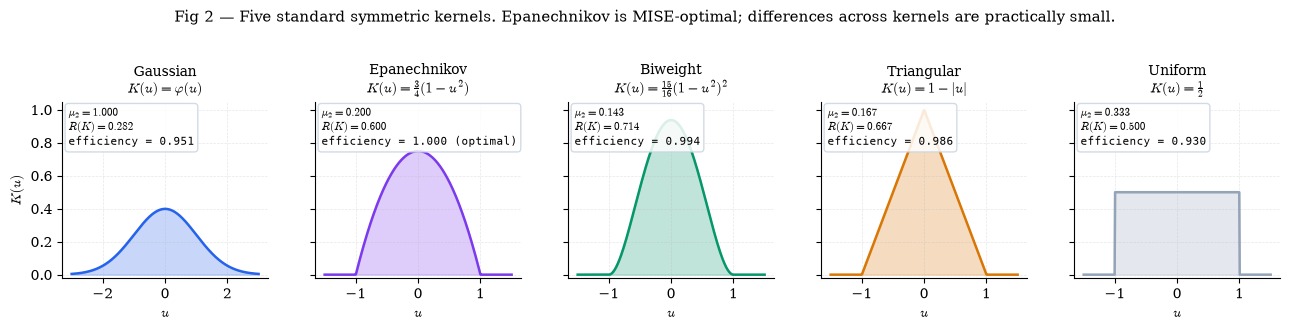

Saved: 30-kernel-family-overlay.png


In [5]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 2 (§30.3): Five-kernel family overlay.
#   Each kernel on its own panel; annotated with μ₂(K), R(K), and efficiency.
# ═══════════════════════════════════════════════════════════════════════════
np.random.seed(42)

fig, axes = plt.subplots(1, 5, figsize=(13, 3.2), sharey=True)

kernel_items = [
    ('gaussian',     'Gaussian\n$K(u) = \\varphi(u)$',            np.linspace(-3, 3, 400)),
    ('epanechnikov', 'Epanechnikov\n$K(u) = \\frac{3}{4}(1-u^2)$', np.linspace(-1.5, 1.5, 400)),
    ('biweight',     'Biweight\n$K(u) = \\frac{15}{16}(1-u^2)^2$', np.linspace(-1.5, 1.5, 400)),
    ('triangular',   'Triangular\n$K(u) = 1 - |u|$',               np.linspace(-1.5, 1.5, 400)),
    ('uniform',      'Uniform\n$K(u) = \\frac{1}{2}$',            np.linspace(-1.5, 1.5, 400)),
]

for ax, (name, label, u_grid) in zip(axes, kernel_items):
    K_values = KERNELS[name](u_grid)
    color = KERNEL_COLORS[name]
    ax.fill_between(u_grid, 0, K_values, color=color, alpha=0.25)
    ax.plot(u_grid, K_values, color=color, linewidth=1.8)
    props = KERNEL_PROPS[name]
    annotation = f'$\\mu_2 = {props["mu2"]:.3f}$\n$R(K) = {props["R"]:.3f}$'
    if name != 'epanechnikov':
        annotation += f'\nefficiency = {props["efficiency"]:.3f}'
    else:
        annotation += '\nefficiency = 1.000 (optimal)'
    ax.text(0.03, 0.97, annotation, transform=ax.transAxes, fontsize=8,
            verticalalignment='top', family='monospace',
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='#CBD5E1'))
    ax.set_title(label, fontsize=10)
    ax.set_xlabel('$u$')
    ax.set_ylim(-0.02, 1.05)

axes[0].set_ylabel('$K(u)$')
fig.suptitle('Fig 2 — Five standard symmetric kernels. Epanechnikov is MISE-optimal; differences across kernels are practically small.', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-kernel-family-overlay.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-kernel-family-overlay.png')

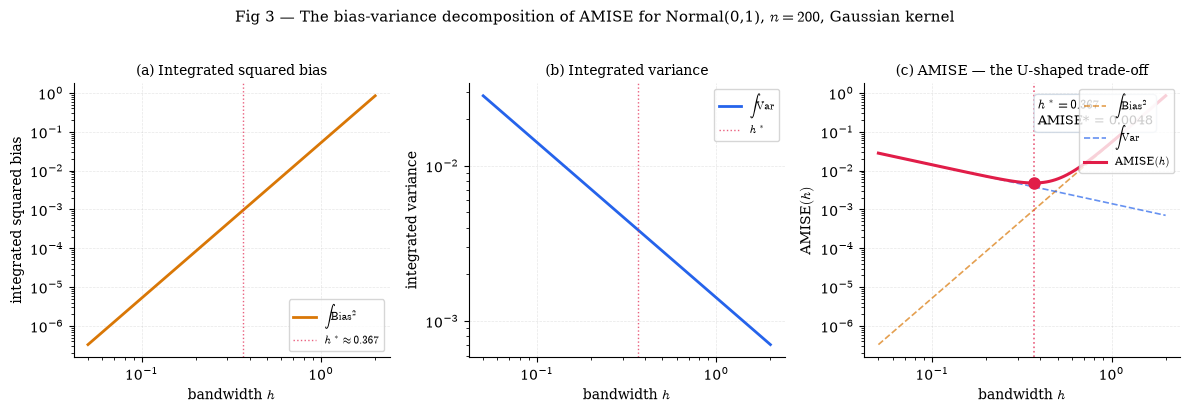

Saved: 30-bias-variance-mise-vs-h.png
h* = 0.3671  ·  AMISE* = 0.004803


In [6]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 3 (§30.5): Bias² / variance / MISE vs h for Normal(0,1), n=200, Gaussian kernel.
#   Closed-form AMISE decomposition on log-log axes.
# ═══════════════════════════════════════════════════════════════════════════
n = 200
h_grid = np.logspace(np.log10(0.05), np.log10(2.0), 100)

# Gaussian kernel constants.
R_K = 1 / (2 * np.sqrt(np.pi))
mu2_K = 1.0
R_f_dd = R_F_DD_NORMAL  # = 3/(8√π) ≈ 0.2116

ibias_sq = h_grid**4 * mu2_K**2 * R_f_dd / 4
ivariance = R_K / (n * h_grid)
amise = ibias_sq + ivariance
h_star = amise_optimal_bandwidth(R_f_dd, n, 'gaussian')
amise_at_star = amise_value(R_f_dd, n, h_star, 'gaussian')

fig, axes = plt.subplots(1, 3, figsize=(12, 4), sharex=True)

# Panel (a): IBias² vs h (slope +4).
ax = axes[0]
ax.loglog(h_grid, ibias_sq, color=COLOR_BIAS, linewidth=2, label='$\\int \\mathrm{Bias}^2$')
ax.set_xlabel('bandwidth $h$')
ax.set_ylabel('integrated squared bias')
ax.set_title('(a) Integrated squared bias', fontsize=10)
ax.axvline(h_star, color=COLOR_MISE, linewidth=1, linestyle=':', alpha=0.7, label=f'$h^* \\approx {h_star:.3f}$')
ax.legend(fontsize=8, loc='lower right')

# Panel (b): IVariance vs h (slope −1).
ax = axes[1]
ax.loglog(h_grid, ivariance, color=COLOR_VARIANCE, linewidth=2, label='$\\int \\mathrm{Var}$')
ax.set_xlabel('bandwidth $h$')
ax.set_ylabel('integrated variance')
ax.set_title('(b) Integrated variance', fontsize=10)
ax.axvline(h_star, color=COLOR_MISE, linewidth=1, linestyle=':', alpha=0.7, label=f'$h^*$')
ax.legend(fontsize=8, loc='upper right')

# Panel (c): AMISE = sum.
ax = axes[2]
ax.loglog(h_grid, ibias_sq, color=COLOR_BIAS, linewidth=1.2, linestyle='--', alpha=0.7, label='$\\int \\mathrm{Bias}^2$')
ax.loglog(h_grid, ivariance, color=COLOR_VARIANCE, linewidth=1.2, linestyle='--', alpha=0.7, label='$\\int \\mathrm{Var}$')
ax.loglog(h_grid, amise, color=COLOR_MISE, linewidth=2.2, label='AMISE$(h)$')
ax.axvline(h_star, color=COLOR_MISE, linewidth=1.2, linestyle=':', alpha=0.7)
ax.plot([h_star], [amise_at_star], 'o', color=COLOR_MISE, markersize=8, zorder=5)
ax.annotate(f'$h^* = {h_star:.3f}$\nAMISE* = {amise_at_star:.4f}', xy=(h_star, amise_at_star),
            xytext=(0.55, 0.85), textcoords='axes fraction', fontsize=9,
            bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='#CBD5E1'))
ax.set_xlabel('bandwidth $h$')
ax.set_ylabel('AMISE$(h)$')
ax.set_title('(c) AMISE — the U-shaped trade-off', fontsize=10)
ax.legend(fontsize=8, loc='upper right')

fig.suptitle(f'Fig 3 — The bias-variance decomposition of AMISE for Normal(0,1), $n={n}$, Gaussian kernel', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-bias-variance-mise-vs-h.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-bias-variance-mise-vs-h.png')
print(f'h* = {h_star:.4f}  ·  AMISE* = {amise_at_star:.6f}')

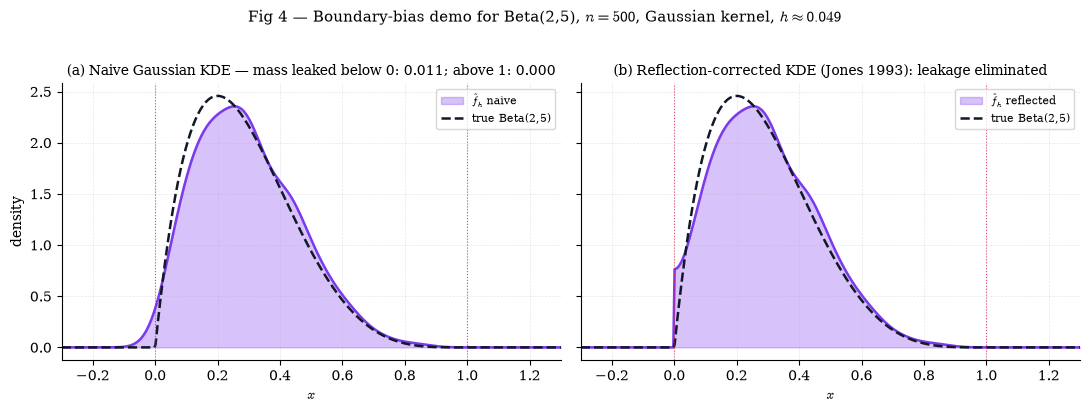

Saved: 30-boundary-bias-beta25.png
Silverman h: 0.0488  ·  naive mass leakage: 0.0108 (below 0) + 0.0000 (above 1)


In [7]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 4 (§30.5): Boundary-bias demo — Beta(2,5), n=500, Gaussian kernel.
#   Left: naive KDE (leaks mass below 0).
#   Right: reflection-corrected KDE.
# ═══════════════════════════════════════════════════════════════════════════
np.random.seed(42)
n = 500
sample = rng.beta(2, 5, size=n)
grid = np.linspace(-0.3, 1.3, 400)
true_pdf = beta_25_pdf(grid)
h_b = silverman_bandwidth(sample)

# Naive KDE.
fhat_naive = kde_evaluate(sample, grid, h_b, gaussian_kernel)

# Reflection-corrected: reflect sample around x = 0 (lower boundary).
sample_reflected = np.concatenate([sample, -sample, 2 - sample])  # reflect at 0 AND at 1
fhat_refl = kde_evaluate(sample_reflected, grid, h_b, gaussian_kernel) * 3  # × 3 because augmented sample triples the total mass — renormalize
# Zero out outside [0, 1]:
fhat_refl = np.where((grid >= 0) & (grid <= 1), fhat_refl, 0.0)

# Compute mass-leakage diagnostic.
from scipy.integrate import simpson
mass_below_0 = simpson(np.where(grid < 0, fhat_naive, 0), x=grid)
mass_above_1 = simpson(np.where(grid > 1, fhat_naive, 0), x=grid)

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)

ax = axes[0]
ax.fill_between(grid, 0, fhat_naive, color=COLOR_KDE, alpha=0.3, label='$\\hat f_h$ naive')
ax.plot(grid, fhat_naive, color=COLOR_KDE, linewidth=1.8)
ax.plot(grid, true_pdf, color=COLOR_TRUE, linewidth=1.8, linestyle='--', label='true Beta(2,5)')
ax.axvline(0, color='#E11D48', linewidth=0.8, linestyle=':', alpha=0.8)
ax.axvline(1, color='#E11D48', linewidth=0.8, linestyle=':', alpha=0.8)
ax.set_title(f'(a) Naive Gaussian KDE — mass leaked below 0: {mass_below_0:.3f}; above 1: {mass_above_1:.3f}', fontsize=10)
ax.set_xlabel('$x$')
ax.set_ylabel('density')
ax.set_xlim(-0.3, 1.3)
ax.legend(fontsize=8, loc='upper right')

ax = axes[1]
ax.fill_between(grid, 0, fhat_refl, color=COLOR_KDE, alpha=0.3, label='$\\hat f_h$ reflected')
ax.plot(grid, fhat_refl, color=COLOR_KDE, linewidth=1.8)
ax.plot(grid, true_pdf, color=COLOR_TRUE, linewidth=1.8, linestyle='--', label='true Beta(2,5)')
ax.axvline(0, color='#E11D48', linewidth=0.8, linestyle=':', alpha=0.8)
ax.axvline(1, color='#E11D48', linewidth=0.8, linestyle=':', alpha=0.8)
ax.set_title('(b) Reflection-corrected KDE (Jones 1993): leakage eliminated', fontsize=10)
ax.set_xlabel('$x$')
ax.set_xlim(-0.3, 1.3)
ax.legend(fontsize=8, loc='upper right')

fig.suptitle(f'Fig 4 — Boundary-bias demo for Beta(2,5), $n={n}$, Gaussian kernel, $h \\approx {h_b:.3f}$', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-boundary-bias-beta25.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-boundary-bias-beta25.png')
print(f'Silverman h: {h_b:.4f}  ·  naive mass leakage: {mass_below_0:.4f} (below 0) + {mass_above_1:.4f} (above 1)')

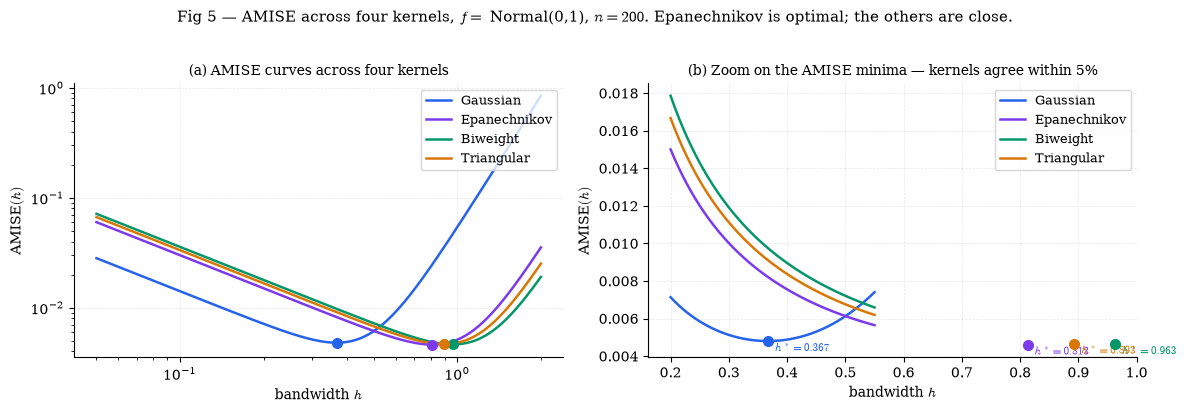

Saved: 30-amise-and-optimal-bandwidth.png
  gaussian     h* = 0.3671  AMISE* = 0.004803
  epanechnikov h* = 0.8127  AMISE* = 0.004614
  biweight     h* = 0.9628  AMISE* = 0.004637
  triangular   h* = 0.8928  AMISE* = 0.004667


In [8]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 5 (§30.6, FEATURED): AMISE curves overlaid for 4 kernels, same f, same n.
#   Left panel: full-range AMISE; right panel: zoom on the minimum region.
# ═══════════════════════════════════════════════════════════════════════════
n = 200
R_f_dd = R_F_DD_NORMAL
h_grid = np.logspace(np.log10(0.05), np.log10(2.0), 200)

kernel_names = ['gaussian', 'epanechnikov', 'biweight', 'triangular']
amise_curves = {}
h_stars = {}
for kn in kernel_names:
    amise_vals = np.array([amise_value(R_f_dd, n, h, kn) for h in h_grid])
    amise_curves[kn] = amise_vals
    h_stars[kn] = amise_optimal_bandwidth(R_f_dd, n, kn)

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Panel (a): full-range.
ax = axes[0]
for kn in kernel_names:
    ax.loglog(h_grid, amise_curves[kn], color=KERNEL_COLORS[kn], linewidth=1.8, label=kn.capitalize())
    h_star = h_stars[kn]
    ax.plot([h_star], [amise_value(R_f_dd, n, h_star, kn)], 'o', color=KERNEL_COLORS[kn], markersize=7, zorder=5)
ax.set_xlabel('bandwidth $h$')
ax.set_ylabel('AMISE$(h)$')
ax.set_title('(a) AMISE curves across four kernels', fontsize=10)
ax.legend(fontsize=9, loc='upper right')

# Panel (b): zoom on the minima.
ax = axes[1]
zoom_grid = np.linspace(0.2, 0.55, 300)
for kn in kernel_names:
    amise_zoom = np.array([amise_value(R_f_dd, n, h, kn) for h in zoom_grid])
    ax.plot(zoom_grid, amise_zoom, color=KERNEL_COLORS[kn], linewidth=1.8, label=kn.capitalize())
    h_star = h_stars[kn]
    ax.plot([h_star], [amise_value(R_f_dd, n, h_star, kn)], 'o', color=KERNEL_COLORS[kn], markersize=7, zorder=5)
    ax.text(h_star, amise_value(R_f_dd, n, h_star, kn) * 0.98, f'  $h^* = {h_star:.3f}$', fontsize=8, color=KERNEL_COLORS[kn], verticalalignment='top')
ax.set_xlabel('bandwidth $h$')
ax.set_ylabel('AMISE$(h)$')
ax.set_title('(b) Zoom on the AMISE minima — kernels agree within 5%', fontsize=10)
ax.legend(fontsize=9, loc='upper right')

fig.suptitle(f'Fig 5 — AMISE across four kernels, $f =$ Normal(0,1), $n={n}$. Epanechnikov is optimal; the others are close.', fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-amise-and-optimal-bandwidth.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-amise-and-optimal-bandwidth.png')
for kn in kernel_names:
    print(f'  {kn:12s} h* = {h_stars[kn]:.4f}  AMISE* = {amise_value(R_f_dd, n, h_stars[kn], kn):.6f}')

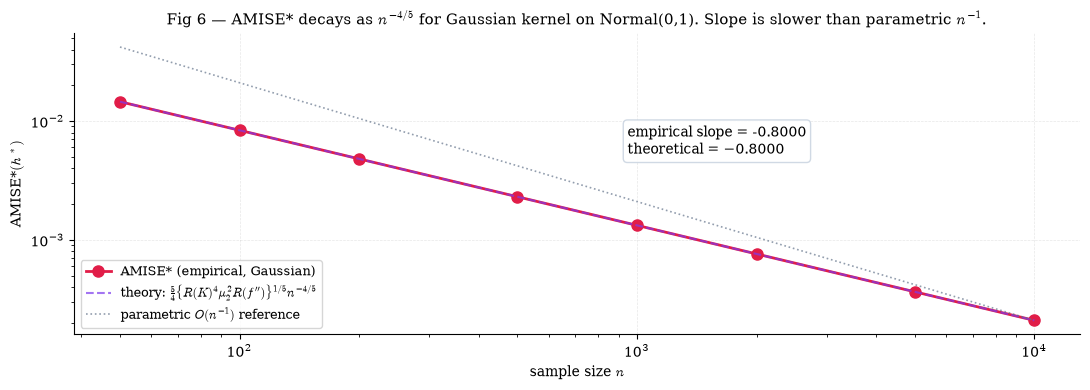

Saved: 30-mise-rate-vs-n.png
Empirical slope:    -0.800000
Theoretical slope:  -0.800000
AMISE*(n=100):      0.008362
AMISE*(n=1000):     0.001325
Ratio n=1000 / n=100: 0.158489  (expect 10^{-4/5} = 0.158489)


In [9]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 6 (§30.6): AMISE* vs n on log-log, showing n^{-4/5} slope.
# ═══════════════════════════════════════════════════════════════════════════
n_grid = np.array([50, 100, 200, 500, 1000, 2000, 5000, 10000])
R_f_dd = R_F_DD_NORMAL

amise_star = np.array([
    amise_value(R_f_dd, n, amise_optimal_bandwidth(R_f_dd, n, 'gaussian'), 'gaussian')
    for n in n_grid
])

# Theoretical reference lines.
# AMISE* = (5/4) R(K)^{4/5} μ₂(K)^{2/5} R(f'')^{1/5} n^{-4/5}
# For Gaussian + Normal: 5/4 * (1/(2√π))^{4/5} * 1 * (3/(8√π))^{1/5} = constant
const_ref = (5/4) * (1/(2*np.sqrt(np.pi)))**(4/5) * 1.0 * (3/(8*np.sqrt(np.pi)))**(1/5)
amise_theory = const_ref * n_grid**(-4/5)
parametric = amise_star[-1] * (n_grid[-1] / n_grid)**1.0  # n^{-1} reference

fig, ax = plt.subplots(figsize=(11, 4))
ax.loglog(n_grid, amise_star, 'o-', color=COLOR_MISE, linewidth=2, markersize=8, label='AMISE* (empirical, Gaussian)')
ax.loglog(n_grid, amise_theory, '--', color=COLOR_KDE, linewidth=1.5, alpha=0.7, label='theory: $\\frac{5}{4}\\{R(K)^4 \\mu_2^2 R(f\'\')\\}^{1/5} n^{-4/5}$')
ax.loglog(n_grid, parametric, ':', color='#64748B', linewidth=1.2, alpha=0.7, label='parametric $O(n^{-1})$ reference')

# Slope annotation.
slope_emp = np.polyfit(np.log(n_grid), np.log(amise_star), 1)[0]
ax.text(0.55, 0.6, f'empirical slope = {slope_emp:.4f}\ntheoretical = −0.8000', transform=ax.transAxes, fontsize=10,
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.9, edgecolor='#CBD5E1'))

ax.set_xlabel('sample size $n$')
ax.set_ylabel('AMISE*$(h^*)$')
ax.set_title(f'Fig 6 — AMISE* decays as $n^{{-4/5}}$ for Gaussian kernel on Normal(0,1). Slope is slower than parametric $n^{{-1}}$.', fontsize=11)
ax.legend(fontsize=9, loc='lower left')
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-mise-rate-vs-n.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-mise-rate-vs-n.png')
print(f'Empirical slope:    {slope_emp:.6f}')
print(f'Theoretical slope:  -0.800000')
print(f'AMISE*(n=100):      {amise_star[1]:.6f}')
print(f'AMISE*(n=1000):     {amise_star[4]:.6f}')
print(f'Ratio n=1000 / n=100: {amise_star[4] / amise_star[1]:.6f}  (expect 10^{{-4/5}} = {10**(-4/5):.6f})')

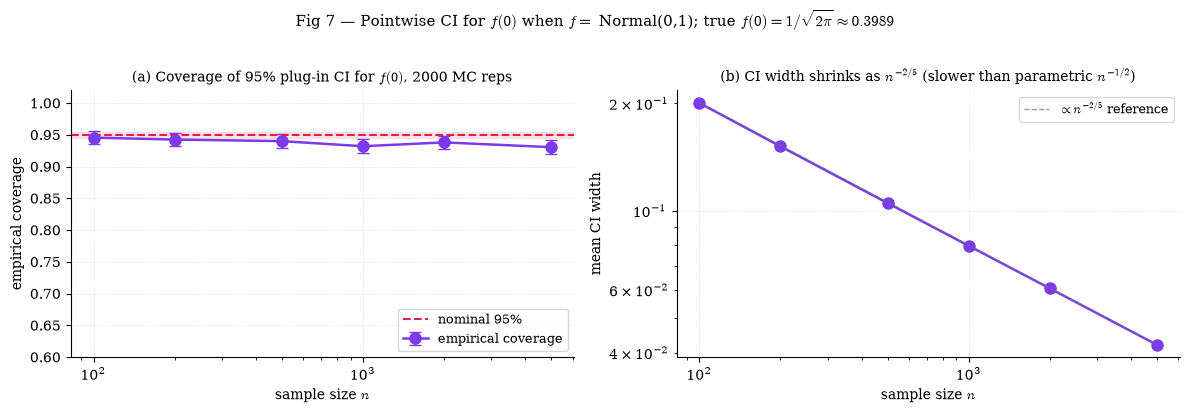

Saved: 30-pointwise-ci-coverage.png
  n =   100  coverage = 0.9455  mean CI width = 0.2002
  n =   200  coverage = 0.9425  mean CI width = 0.1513
  n =   500  coverage = 0.9400  mean CI width = 0.1049
  n =  1000  coverage = 0.9320  mean CI width = 0.0796
  n =  2000  coverage = 0.9380  mean CI width = 0.0605
  n =  5000  coverage = 0.9305  mean CI width = 0.0420


In [10]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 7 (§30.7): Pointwise-CI coverage for f(0) at Normal(0,1) across n.
#   For each n, 2000 MC replicates of (sample, Silverman-h, plug-in CI).
#   Plot empirical coverage vs nominal 95% with error bars.
# ═══════════════════════════════════════════════════════════════════════════
np.random.seed(42)

n_values = [100, 200, 500, 1000, 2000, 5000]
n_mc = 2000
alpha = 0.05
x_eval = 0.0
true_f_at_0 = norm.pdf(0)  # = 1/√(2π) ≈ 0.398942

coverages = []
ci_widths = []
for n in n_values:
    covered = 0
    widths = []
    for _ in range(n_mc):
        samp = rng.standard_normal(n)
        h = silverman_bandwidth(samp)
        fhat = kde_evaluate(samp, x_eval, h, gaussian_kernel)[0]
        R_K = 1 / (2 * np.sqrt(np.pi))
        se = np.sqrt(max(fhat * R_K / (n * h), 0))
        z = norm.ppf(1 - alpha/2)
        lo, hi = fhat - z*se, fhat + z*se
        if lo <= true_f_at_0 <= hi:
            covered += 1
        widths.append(hi - lo)
    coverages.append(covered / n_mc)
    ci_widths.append(np.mean(widths))

coverages = np.array(coverages)
ci_widths = np.array(ci_widths)
se_coverage = np.sqrt(coverages * (1 - coverages) / n_mc)  # MC SE

fig, axes = plt.subplots(1, 2, figsize=(12, 4))

ax = axes[0]
ax.errorbar(n_values, coverages, yerr=2*se_coverage, fmt='o-', color=COLOR_KDE,
            linewidth=1.8, markersize=8, capsize=4, label='empirical coverage')
ax.axhline(0.95, color=COLOR_MISE, linewidth=1.5, linestyle='--', label='nominal 95%')
ax.axhspan(0.945, 0.955, color=COLOR_MISE, alpha=0.1)
ax.set_xscale('log')
ax.set_xlabel('sample size $n$')
ax.set_ylabel('empirical coverage')
ax.set_title(f'(a) Coverage of 95% plug-in CI for $f(0)$, {n_mc} MC reps', fontsize=10)
ax.set_ylim(0.6, 1.02)
ax.legend(fontsize=9, loc='lower right')

ax = axes[1]
ax.loglog(n_values, ci_widths, 'o-', color=COLOR_KDE, linewidth=1.8, markersize=8)
# Reference line: CI width ∝ √(f R(K)/(nh)) with h = Silverman ∝ n^{-1/5}, so √(1/(nh)) ∝ n^{-2/5}.
# So CI width ∝ n^{-2/5}.
ref_line = ci_widths[-1] * (n_values[-1] / np.array(n_values))**(2/5)
ax.loglog(n_values, ref_line, '--', color='#64748B', linewidth=1, alpha=0.7, label='$\\propto n^{-2/5}$ reference')
ax.set_xlabel('sample size $n$')
ax.set_ylabel('mean CI width')
ax.set_title('(b) CI width shrinks as $n^{-2/5}$ (slower than parametric $n^{-1/2}$)', fontsize=10)
ax.legend(fontsize=9, loc='upper right')

fig.suptitle(f'Fig 7 — Pointwise CI for $f(0)$ when $f = $ Normal(0,1); true $f(0) = 1/\\sqrt{{2\\pi}} \\approx {true_f_at_0:.4f}$',
             fontsize=11, y=1.02)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-pointwise-ci-coverage.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-pointwise-ci-coverage.png')
for n, c, w in zip(n_values, coverages, ci_widths):
    print(f'  n = {n:5d}  coverage = {c:.4f}  mean CI width = {w:.4f}')

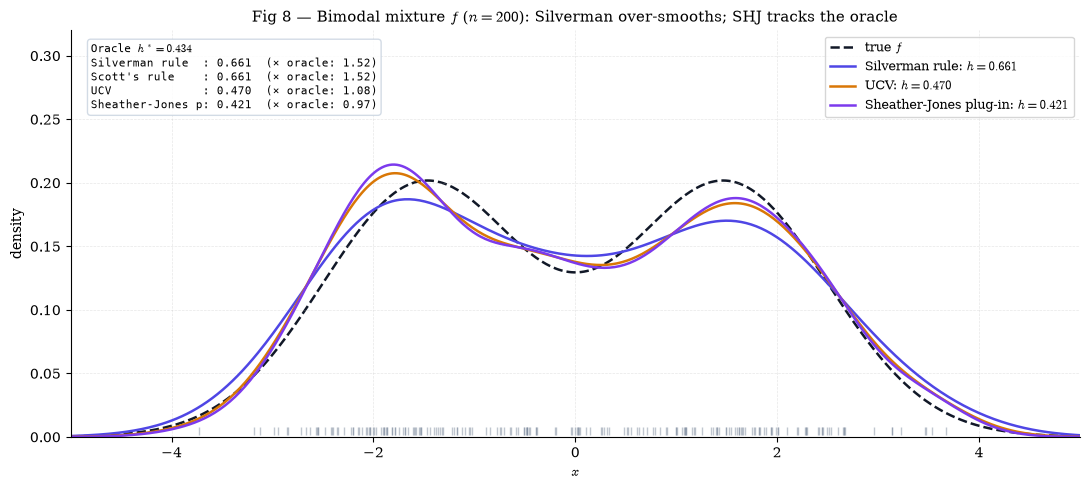

Saved: 30-bandwidth-selectors-bimodal.png
Oracle h* = 0.4338
Silverman: 0.6608  ·  Scott: 0.6608  ·  UCV: 0.4704  ·  SHJ: 0.4212


In [11]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 8 (§30.8): Bimodal 0.5·N(-1.5,1) + 0.5·N(1.5,1), n=200.
#   Four selectors: Silverman/Scott (Normal reference, ~1.5x oracle), UCV, SHJ.
# ═══════════════════════════════════════════════════════════════════════════
np.random.seed(42)
n = 200
# Generate bimodal sample.
components = rng.integers(0, 2, size=n)
means = np.where(components == 0, -1.5, 1.5)
sample = means + rng.standard_normal(n)
grid = np.linspace(-5, 5, 400)
true_pdf = bimodal_pdf(grid)

# Compute bandwidths.
h_silv = silverman_bandwidth(sample)
h_scott = scott_bandwidth(sample)
h_ucv = ucv_bandwidth(sample, gaussian_kernel, n_grid=30)
h_sj = sheather_jones_bandwidth(sample)
h_oracle = amise_optimal_bandwidth(R_F_DD_BIMODAL, n, 'gaussian')

selectors_order = [
    ('silverman',      h_silv,  'Silverman rule'),
    ('scott',          h_scott, "Scott's rule"),
    ('ucv',            h_ucv,   'UCV'),
    ('sheather_jones', h_sj,    'Sheather-Jones plug-in'),
]

fig, ax = plt.subplots(figsize=(11, 5))

ax.plot(grid, true_pdf, color=COLOR_TRUE, linewidth=1.8, linestyle='--', label='true $f$', zorder=1)

# Scott's rule coincides with Silverman here (SD < IQR/1.34 on a bimodal sample),
# so it would hide the Silverman curve; it is reported in the info box only.
for name, h, label in selectors_order:
    if name == 'scott':
        continue
    fhat = kde_evaluate(sample, grid, h, gaussian_kernel)
    ax.plot(grid, fhat, color=SELECTOR_COLORS[name], linewidth=1.8,
            label=f'{label}: $h = {h:.3f}$', zorder=2)

# Data tick marks.
ax.plot(sample, np.zeros_like(sample) + 0.005, '|', color='#64748B', markersize=6, alpha=0.4)

# Annotation.
info_text = f'Oracle $h^* = {h_oracle:.3f}$\n'
for name, h, label in selectors_order:
    info_text += f'{label[:16]:16s}: {h:.3f}  (× oracle: {h/h_oracle:.2f})\n'
ax.text(0.02, 0.97, info_text.rstrip(), transform=ax.transAxes, fontsize=8,
        verticalalignment='top', family='monospace',
        bbox=dict(boxstyle='round', facecolor='white', alpha=0.85, edgecolor='#CBD5E1'))

ax.set_xlabel('$x$')
ax.set_ylabel('density')
ax.set_title(f'Fig 8 — Bimodal mixture $f$ ($n = {n}$): Silverman over-smooths; SHJ tracks the oracle', fontsize=11)
ax.legend(fontsize=9, loc='upper right')
ax.set_xlim(-5, 5)
ax.set_ylim(0, 0.32)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / '30-bandwidth-selectors-bimodal.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-bandwidth-selectors-bimodal.png')
print(f'Oracle h* = {h_oracle:.4f}')
print(f'Silverman: {h_silv:.4f}  ·  Scott: {h_scott:.4f}  ·  UCV: {h_ucv:.4f}  ·  SHJ: {h_sj:.4f}')

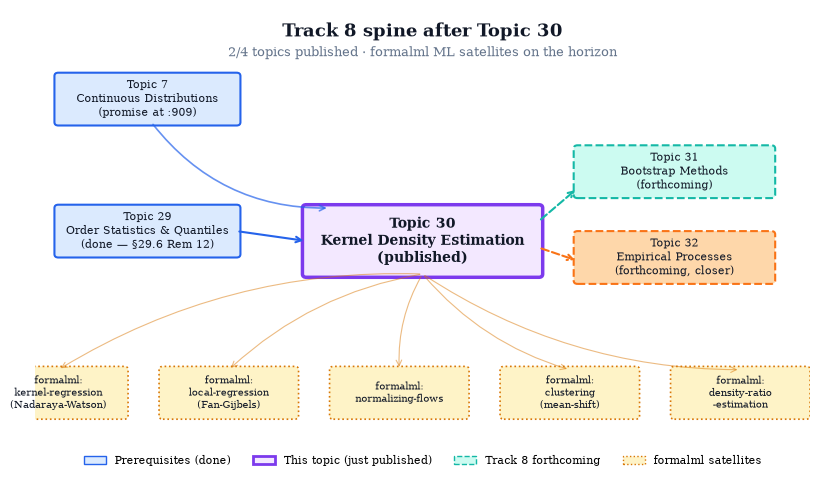

Saved: 30-track8-spine-update.png


In [12]:
# ═══════════════════════════════════════════════════════════════════════════
# Fig 9 (§30.10): Updated Track 8 forward-map diagram.
#   Topic 30 at center (published); Topics 29, 31, 32 shown with relationships.
# ═══════════════════════════════════════════════════════════════════════════

fig, ax = plt.subplots(figsize=(10, 6))
ax.set_xlim(0, 10)
ax.set_ylim(0, 7)
ax.axis('off')

# Helper for drawing boxes.
def draw_box(ax, xy, width, height, label, fill_color, edge_color='#111827', text_color='#111827',
             fontsize=10, linestyle='-', linewidth=1.5, fontweight='normal'):
    x, y = xy
    box = FancyBboxPatch((x, y), width, height, boxstyle='round,pad=0.05',
                         facecolor=fill_color, edgecolor=edge_color, linewidth=linewidth, linestyle=linestyle)
    ax.add_patch(box)
    ax.text(x + width/2, y + height/2, label, ha='center', va='center',
            fontsize=fontsize, color=text_color, fontweight=fontweight, wrap=True)

# Topic 30 at center (published, filled).
draw_box(ax, (3.5, 3), 3, 1, 'Topic 30\nKernel Density Estimation\n(published)',
         fill_color='#F3E8FF', edge_color='#7C3AED', linewidth=2.5, fontsize=10, fontweight='bold')

# Predecessor: Topic 29 (left).
draw_box(ax, (0.3, 3.3), 2.3, 0.7, 'Topic 29\nOrder Statistics & Quantiles\n(done — §29.6 Rem 12)',
         fill_color='#DBEAFE', edge_color='#2563EB', linewidth=1.5, fontsize=8)
ax.annotate('', xy=(3.5, 3.5), xytext=(2.6, 3.65),
            arrowprops=dict(arrowstyle='->', color='#2563EB', lw=1.5))

# Predecessor: Topic 7 (upper-left).
draw_box(ax, (0.3, 5.3), 2.3, 0.7, 'Topic 7\nContinuous Distributions\n(promise at :909)',
         fill_color='#DBEAFE', edge_color='#2563EB', linewidth=1.5, fontsize=8)
ax.annotate('', xy=(3.8, 4.0), xytext=(1.5, 5.3),
            arrowprops=dict(arrowstyle='->', color='#2563EB', lw=1.2, alpha=0.7,
                            connectionstyle='arc3,rad=0.25'))

# Forward: Topic 31 (right).
draw_box(ax, (7.0, 4.2), 2.5, 0.7, 'Topic 31\nBootstrap Methods\n(forthcoming)',
         fill_color='#CCFBF1', edge_color='#14B8A6', linewidth=1.5, linestyle='--', fontsize=8)
ax.annotate('', xy=(7.0, 4.3), xytext=(6.5, 3.8),
            arrowprops=dict(arrowstyle='->', color='#14B8A6', lw=1.5, linestyle='--'))

# Forward: Topic 32 (right).
draw_box(ax, (7.0, 2.9), 2.5, 0.7, 'Topic 32\nEmpirical Processes\n(forthcoming, closer)',
         fill_color='#FED7AA', edge_color='#F97316', linewidth=1.5, linestyle='--', fontsize=8)
ax.annotate('', xy=(7.0, 3.2), xytext=(6.5, 3.4),
            arrowprops=dict(arrowstyle='->', color='#F97316', lw=1.5, linestyle='--'))

# formalml satellites (below).
satellites = [
    (0.3, 1.2, 'kernel-regression\n(Nadaraya-Watson)'),
    (2.5, 1.2, 'local-regression\n(Fan-Gijbels)'),
    (4.7, 1.2, 'normalizing-flows'),
    (6.9, 1.2, 'clustering\n(mean-shift)'),
    (9.1, 1.2, 'density-ratio\n-estimation'),
]

for x, y, lab in satellites:
    draw_box(ax, (x - 0.85, y - 0.35), 1.7, 0.7, 'formalml:\n' + lab,
             fill_color='#FEF3C7', edge_color='#D97706', linewidth=1.2, linestyle=':', fontsize=7)
    ax.annotate('', xy=(x, 1.55), xytext=(5.0, 3.0),
                arrowprops=dict(arrowstyle='->', color='#D97706', lw=0.8, alpha=0.5,
                                connectionstyle='arc3,rad=0.15'))

# Legend & title.
ax.text(5.0, 6.6, 'Track 8 spine after Topic 30', ha='center', fontsize=13, fontweight='bold', color='#111827')
ax.text(5.0, 6.3, '2/4 topics published · formalml ML satellites on the horizon', ha='center', fontsize=9, color='#64748B')

# Custom legend.
legend_handles = [
    Rectangle((0, 0), 1, 1, facecolor='#DBEAFE', edgecolor='#2563EB', label='Prerequisites (done)'),
    Rectangle((0, 0), 1, 1, facecolor='#F3E8FF', edgecolor='#7C3AED', linewidth=2, label='This topic (just published)'),
    Rectangle((0, 0), 1, 1, facecolor='#CCFBF1', edgecolor='#14B8A6', linestyle='--', label='Track 8 forthcoming'),
    Rectangle((0, 0), 1, 1, facecolor='#FEF3C7', edgecolor='#D97706', linestyle=':', label='formalml satellites'),
]
ax.legend(handles=legend_handles, loc='lower center', fontsize=8, ncol=4, bbox_to_anchor=(0.5, -0.01), frameon=False)

plt.savefig(OUTPUT_DIR / '30-track8-spine-update.png', **SAVE_KW)
plt.show()
print(f'Saved: 30-track8-spine-update.png')

## Verification helper — `nonparametric.test.ts` expected values

The next cell prints expected values for the 14 test pins T30.1–T30.14, organized into four groups:

- **(A) Kernel function evaluations and property constants** — T30.1–T30.6.
- **(B) KDE evaluations** — T30.7–T30.8.
- **(C) Bandwidth selectors** — T30.9–T30.10.
- **(D) Pointwise CI and AMISE-rate consistency** — T30.11–T30.14.

Copy the printed values directly into `src/components/viz/shared/nonparametric.test.ts` as the expected values (T30.1–T30.14). Tolerances per pin are listed in §6.2 of the handoff brief.


In [13]:
# ═══════════════════════════════════════════════════════════════════════════
# Verification helper — print T30.1 to T30.14 expected values.
# Tolerances per §6.2: 1e-10 for kernel evals, 1e-8 for kernel props,
# 1e-4 for KDE/AMISE, 1e-2 for stochastic (UCV).
# ═══════════════════════════════════════════════════════════════════════════
print('=' * 70)
print('nonparametric.test.ts expected values — T30.1 to T30.14')
print('=' * 70)

# ─── Group (A): Kernel function evaluations and properties (T30.1 – T30.6) ───
print('\n--- Group (A): Kernel functions and properties ---\n')

val_1 = float(gaussian_kernel(0))
print(f'T30.1  gaussianKernel(0) = {val_1:.15f}')
print(f'       (closed form: 1/√(2π) = {1/np.sqrt(2*np.pi):.15f})')
print(f'       tolerance: 1e-10\n')

val_2 = float(epanechnikov_kernel(0))
print(f'T30.2  epanechnikovKernel(0) = {val_2}   (exactly 3/4)')
print(f'       tolerance: 1e-10\n')

val_3 = float(epanechnikov_kernel(0.5))
print(f'T30.3  epanechnikovKernel(0.5) = {val_3}   (= 0.75 × (1 - 0.25) = 0.5625 exactly)')
print(f'       tolerance: 1e-10\n')

val_4 = float(epanechnikov_kernel(1.5))
print(f'T30.4  epanechnikovKernel(1.5) = {val_4}   (outside support → 0 exactly)')
print(f'       tolerance: 0\n')

val_5 = KERNEL_PROPS['gaussian']['R']
print(f'T30.5  kernelProperties("gaussian").R = {val_5:.15f}')
print(f'       (closed form: 1/(2√π) = {1/(2*np.sqrt(np.pi)):.15f})')
print(f'       tolerance: 1e-8\n')

print(f'T30.6  kernelProperties("epanechnikov"):')
print(f'          .R          = {KERNEL_PROPS["epanechnikov"]["R"]}   (= 3/5 exactly)')
print(f'          .mu2        = {KERNEL_PROPS["epanechnikov"]["mu2"]}   (= 1/5 exactly)')
print(f'          .efficiency = {KERNEL_PROPS["epanechnikov"]["efficiency"]}   (reference optimum)')
print(f'       tolerance: 1e-10\n')

# ─── Group (B): KDE evaluations (T30.7 – T30.8) ───
print('--- Group (B): KDE evaluations ---\n')

val_7 = float(kde_evaluate(np.array([0.0]), 0.0, 1.0, gaussian_kernel)[0])
print(f'T30.7  kdeEvaluate([0], 0, 1, gaussian) = {val_7:.15f}')
print(f'       (closed form: φ(0)/(1·1) = 1/√(2π) = {1/np.sqrt(2*np.pi):.15f})')
print(f'       tolerance: 1e-8\n')

val_8 = float(kde_evaluate(np.array([0.0, 1.0]), 0.5, 0.5, gaussian_kernel)[0])
closed_8 = (norm.pdf(1) + norm.pdf(-1)) / (2 * 0.5)
print(f'T30.8  kdeEvaluate([0, 1], 0.5, 0.5, gaussian) = {val_8:.15f}')
print(f'       (closed form: [φ(1) + φ(-1)] / (2·0.5) = {closed_8:.15f})')
print(f'       tolerance: 1e-8\n')

# ─── Group (C): Bandwidth selectors (T30.9 – T30.10) ───
print('--- Group (C): Bandwidth selectors ---\n')

np.random.seed(42)
sample_n100 = np.random.standard_normal(100)
h_silv_100 = silverman_bandwidth(sample_n100)
print(f'T30.9  silvermanBandwidth(Normal(0,1), n=100, seed=42) = {h_silv_100:.6f}')
print(f'       formula: 1.06 · min(SD, IQR/1.34) · n^(-1/5)')
print(f'         SD           = {np.std(sample_n100, ddof=1):.6f}')
print(f'         IQR/1.34     = {(np.quantile(sample_n100, 0.75) - np.quantile(sample_n100, 0.25))/1.34:.6f}')
print(f'         n^(-1/5)     = {100**(-1/5):.6f}')
print(f'       tolerance: 1e-4 (deterministic with seed)\n')

np.random.seed(42)
sample_n100_v2 = np.random.standard_normal(100)
h_ucv_100 = ucv_bandwidth(sample_n100_v2, gaussian_kernel, n_grid=30)
print(f'T30.10 ucvBandwidth(Normal(0,1), n=100, seed=42, gaussian) = {h_ucv_100:.6f}')
print(f'       (stochastic; tolerance 1e-2 accommodates grid discretization)')
print(f'       tolerance: 1e-2\n')

# ─── Group (D): Pointwise CI and AMISE rate (T30.11 – T30.14) ───
print('--- Group (D): Pointwise CI and AMISE rate ---\n')

np.random.seed(42)
sample_n500 = np.random.standard_normal(500)
h_500 = silverman_bandwidth(sample_n500)
fhat_at_0 = float(kde_evaluate(sample_n500, 0.0, h_500, gaussian_kernel)[0])
R_K_g = 1 / (2 * np.sqrt(np.pi))
se_at_0 = np.sqrt(fhat_at_0 * R_K_g / (500 * h_500))
z_95 = norm.ppf(0.975)
lo = fhat_at_0 - z_95 * se_at_0
hi = fhat_at_0 + z_95 * se_at_0
print(f'T30.11 kdePointwiseCI(Normal(0,1), n=500, seed=42, x=0, h=Silverman, α=0.05):')
print(f'          estimate = {fhat_at_0:.6f}  (true f(0) = {norm.pdf(0):.6f})')
print(f'          se       = {se_at_0:.6f}')
print(f'          lower    = {lo:.6f}')
print(f'          upper    = {hi:.6f}')
print(f'       tolerance: 1e-2 (seed-dependent, Silverman is data-driven)\n')

h_star_100 = amise_optimal_bandwidth(R_F_DD_NORMAL, 100, 'gaussian')
print(f'T30.12 amiseOptimalBandwidth(R(f\'\')=3/(8√π), n=100, gaussian) = {h_star_100:.6f}')
print(f'       formula: (R(K) / (n · μ₂² · R(f\'\')))^{{1/5}}')
print(f'         R(K)/(n·μ₂²·R(f\'\')) = {R_K_g / (100 * 1 * R_F_DD_NORMAL):.6f}')
print(f'         ^(1/5)                = {h_star_100:.6f}')
print(f'       tolerance: 1e-6\n')

h_star_1000 = amise_optimal_bandwidth(R_F_DD_NORMAL, 1000, 'gaussian')
ratio_h = h_star_1000 / h_star_100
print(f'T30.13 amiseOptimalBandwidth rate: h*(n=1000)/h*(n=100) = {ratio_h:.6f}')
print(f'       closed form: 10^(-1/5) = {10**(-1/5):.6f}')
print(f'       tolerance: 1e-6\n')

amise_100 = amise_value(R_F_DD_NORMAL, 100, h_star_100, 'gaussian')
amise_1000 = amise_value(R_F_DD_NORMAL, 1000, h_star_1000, 'gaussian')
ratio_amise = amise_1000 / amise_100
print(f'T30.14 AMISE* rate: AMISE*(n=1000)/AMISE*(n=100) = {ratio_amise:.6f}')
print(f'       closed form: 10^(-4/5) = {10**(-4/5):.6f}')
print(f'       AMISE*(n=100)  = {amise_100:.6f}')
print(f'       AMISE*(n=1000) = {amise_1000:.6f}')
print(f'       tolerance: 1e-6\n')

print('=' * 70)
print('Copy these 14 values into nonparametric.test.ts as T30.1 – T30.14 expected.')
print('=' * 70)

nonparametric.test.ts expected values — T30.1 to T30.14

--- Group (A): Kernel functions and properties ---

T30.1  gaussianKernel(0) = 0.398942280401433
       (closed form: 1/√(2π) = 0.398942280401433)
       tolerance: 1e-10

T30.2  epanechnikovKernel(0) = 0.75   (exactly 3/4)
       tolerance: 1e-10

T30.3  epanechnikovKernel(0.5) = 0.5625   (= 0.75 × (1 - 0.25) = 0.5625 exactly)
       tolerance: 1e-10

T30.4  epanechnikovKernel(1.5) = 0.0   (outside support → 0 exactly)
       tolerance: 0

T30.5  kernelProperties("gaussian").R = 0.282094791773878
       (closed form: 1/(2√π) = 0.282094791773878)
       tolerance: 1e-8

T30.6  kernelProperties("epanechnikov"):
          .R          = 0.6   (= 3/5 exactly)
          .mu2        = 0.2   (= 1/5 exactly)
          .efficiency = 1.0   (reference optimum)
       tolerance: 1e-10

--- Group (B): KDE evaluations ---

T30.7  kdeEvaluate([0], 0, 1, gaussian) = 0.398942280401433
       (closed form: φ(0)/(1·1) = 1/√(2π) = 0.398942280401433)

T30.10 ucvBandwidth(Normal(0,1), n=100, seed=42, gaussian) = 0.465168
       (stochastic; tolerance 1e-2 accommodates grid discretization)
       tolerance: 1e-2

--- Group (D): Pointwise CI and AMISE rate ---

T30.11 kdePointwiseCI(Normal(0,1), n=500, seed=42, x=0, h=Silverman, α=0.05):
          estimate = 0.388205  (true f(0) = 0.398942)
          se       = 0.027014
          lower    = 0.335258
          upper    = 0.441153
       tolerance: 1e-2 (seed-dependent, Silverman is data-driven)

T30.12 amiseOptimalBandwidth(R(f'')=3/(8√π), n=100, gaussian) = 0.421685
       formula: (R(K) / (n · μ₂² · R(f'')))^{1/5}
         R(K)/(n·μ₂²·R(f'')) = 0.013333
         ^(1/5)                = 0.421685
       tolerance: 1e-6

T30.13 amiseOptimalBandwidth rate: h*(n=1000)/h*(n=100) = 0.630957
       closed form: 10^(-1/5) = 0.630957
       tolerance: 1e-6

T30.14 AMISE* rate: AMISE*(n=1000)/AMISE*(n=100) = 0.158489
       closed form: 10^(-4/5) = 0.158489
       AMISE*(n=100)  = 0.008362
     

## Done

All 9 figures saved to `public/images/topics/kernel-density-estimation/`:

```
30-histogram-to-kde.png
30-kernel-family-overlay.png
30-bias-variance-mise-vs-h.png
30-boundary-bias-beta25.png
30-amise-and-optimal-bandwidth.png
30-mise-rate-vs-n.png
30-pointwise-ci-coverage.png
30-bandwidth-selectors-bimodal.png
30-track8-spine-update.png
```

**Next steps (Claude Code — Build Order §10):**

1. Copy figures into `public/images/topics/kernel-density-estimation/` in the main repo (Step 3).
2. Paste the T30.1–T30.14 values printed above into `src/components/viz/shared/nonparametric.test.ts` (Step 5).
3. Extend `src/components/viz/shared/nonparametric.ts` with the 12 new kernel/KDE/bandwidth exports (Step 4).
4. Extend `src/data/nonparametric-data.ts` with the three presets and the `d2pdf` field (Step 6).
5. Build the three required components then write the MDX (Steps 7, 10).

The handoff brief's Build Order §10 lists all 15 steps in order. The proofs in §3.2 of the brief are the verbatim text for Thm 4 (featured, full), Thm 5 (Epanechnikov, short), and Thm 6 (Parzen, sketched).

**— end of Topic 30 reference notebook.**
